# The binary classification fabrication problem, illustrated

**The punchline:** binary classification only has two labels, 0 or 1. It has
no label for "we don't know yet." So every customer whose fate is genuinely
unresolved gets forcibly folded into label = 0 ("not churned") — not because
we know they're safe, but because that's the only bucket available for
"unknown." This notebook makes that fabrication visible and quantifies it,
using the real Telco dataset.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
# df = df.dropna(subset=["TotalCharges"])
# df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

# print(f"Total customers: {len(df):,}")

In [15]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

In [16]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [18]:
six_month_surv_df = df[['customerID','tenure','Churn']].copy()



In [19]:
six_month_surv_df['Binary Class_Churned within or survived beyond six months'] = np.where ((six_month_surv_df['tenure']<=6)
                                                                              & (six_month_surv_df['Churn']=='Yes'), 'Churned within 6 months', 'Survived beyond 6 momths')

In [20]:
six_month_surv_df.head()

,customerID,tenure,Churn,Binary Class_Churned within or survived beyond six months
0,7590-VHVEG,1,No,Survived beyond 6 momths
1,5575-GNVDE,34,No,Survived beyond 6 momths
2,3668-QPYBK,2,Yes,Churned within 6 months
3,7795-CFOCW,45,No,Survived beyond 6 momths
4,9237-HQITU,2,Yes,Churned within 6 months


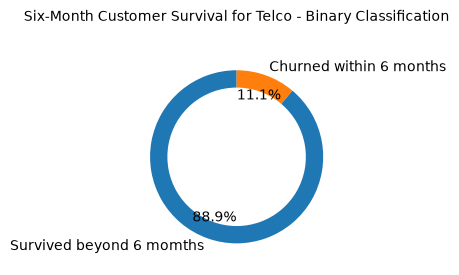

In [21]:
import matplotlib.pyplot as plt

# Count each category
counts = six_month_surv_df[
    'Binary Class_Churned within or survived beyond six months'
].value_counts()

# Plot
fig, ax = plt.subplots(figsize=(4, 4))

ax.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.2),
    pctdistance=0.75
)

ax.set_title(
    'Six-Month Customer Survival for Telco - Binary Classification',
    fontsize=10,
    pad=20
)

plt.tight_layout()
plt.show()

In [22]:
conditions = [
    (six_month_surv_df['tenure'] <= 6) & (six_month_surv_df['Churn'] == 'Yes'),
    (six_month_surv_df['tenure'] <= 6) & (six_month_surv_df['Churn'] == 'No'),
    (six_month_surv_df['tenure'] > 6)
]

choices = [
    'Churned within 6 months',
    'Unsure if survived beyond 6 months (binary sees this as not churned)',
    'Survived beyond 6 months'
]

six_month_surv_df['True class_Churned_Survived_Unsure_6 months'] = np.select(
    conditions,
    choices,
    default='Unknown'
)

In [23]:
six_month_surv_df.head()

,customerID,tenure,Churn,Binary Class_Churned within or survived beyond six months,True class_Churned_Survived_Unsure_6 months
0,7590-VHVEG,1,No,Survived beyond 6 momths,Unsure if survived beyond 6 months (binary see...
1,5575-GNVDE,34,No,Survived beyond 6 momths,Survived beyond 6 months
2,3668-QPYBK,2,Yes,Churned within 6 months,Churned within 6 months
3,7795-CFOCW,45,No,Survived beyond 6 momths,Survived beyond 6 months
4,9237-HQITU,2,Yes,Churned within 6 months,Churned within 6 months


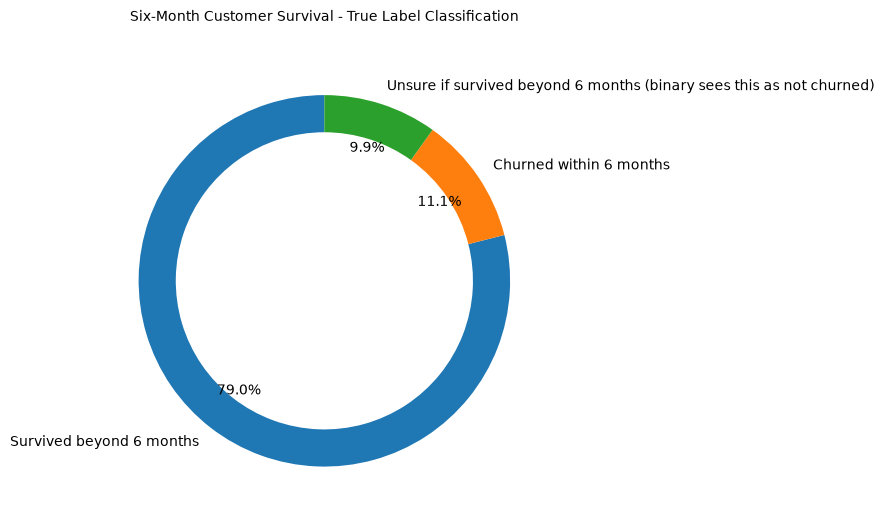

In [24]:


column = 'True class_Churned_Survived_Unsure_6 months'

counts = six_month_surv_df[column].value_counts()

fig, ax = plt.subplots(figsize=(8,8))

ax.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.2),
    pctdistance=0.75
)

ax.set_title(
    'Six-Month Customer Survival - True Label Classification',
    fontsize=10,
    pad=20
)

plt.tight_layout()
plt.show()

In [25]:
# -----------------------------------
# 1. Create separate dataframe
# -----------------------------------

survival_horizon_df = df[
    ['customerID', 'tenure', 'Churn']
].copy()


# -----------------------------------
# 2. Define time horizons
# -----------------------------------

months = [3, 6, 12, 18, 24, 36]

results = []


# -----------------------------------
# 3. Calculate outcomes
# -----------------------------------

for month in months:

    # Churned by this month
    churned_count = (
        (survival_horizon_df['tenure'] <= month) &
        (survival_horizon_df['Churn'] == 'Yes')
    ).sum()

    # Active but has not yet reached this month
    unsure_count = (
        (survival_horizon_df['tenure'] <= month) &
        (survival_horizon_df['Churn'] == 'No')
    ).sum()

    # Has survived beyond this month
    survived_count = (
        survival_horizon_df['tenure'] > month
    ).sum()

    total = len(survival_horizon_df)

    results.append({
        'Month': month,
        'Churned': churned_count / total * 100,
        'Unsure': unsure_count / total * 100,
        'Survived': survived_count / total * 100
    })


results_df = pd.DataFrame(results)



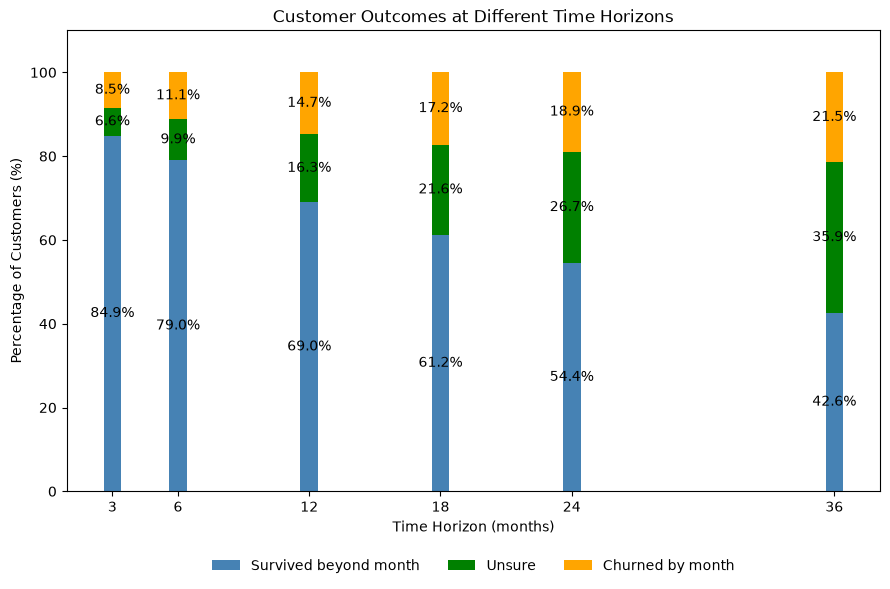

In [26]:
# -----------------------------------
# 4. Plot stacked bars
# -----------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

# Survived
ax.bar(
    results_df['Month'],
    results_df['Survived'],
    label='Survived beyond month',
    color='steelblue'
)

# Unsure
ax.bar(
    results_df['Month'],
    results_df['Unsure'],
    bottom=results_df['Survived'],
    label='Unsure',
    color='green'
)

# Churned
ax.bar(
    results_df['Month'],
    results_df['Churned'],
    bottom=(
        results_df['Survived'] +
        results_df['Unsure']
    ),
    label='Churned by month',
    color='orange'
)


# -----------------------------------
# 5. Add percentages
# -----------------------------------

for i, month in enumerate(months):

    s = results_df.iloc[i]['Survived']
    u = results_df.iloc[i]['Unsure']
    c = results_df.iloc[i]['Churned']

    # Survived %
    if s > 3:
        ax.text(
            month,
            s / 2,
            f'{s:.1f}%',
            ha='center',
            va='center'
        )

    # Unsure %
    if u > 3:
        ax.text(
            month,
            s + u / 2,
            f'{u:.1f}%',
            ha='center',
            va='center'
        )

    # Churned %
    if c > 3:
        ax.text(
            month,
            s + u + c / 2,
            f'{c:.1f}%',
            ha='center',
            va='center'
        )


# -----------------------------------
# 6. Formatting
# -----------------------------------

ax.set_xlabel('Time Horizon (months)')
ax.set_ylabel('Percentage of Customers (%)')

ax.set_title(
    'Customer Outcomes at Different Time Horizons'
)

ax.set_xticks(months)
ax.set_ylim(0, 110)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)

plt.tight_layout()
plt.show()

## 3. What binary classification actually reports: two bars, two categories

This is the naive framing a product manager would see — "churned" vs "not
churned" — with the unknown customers silently folded into "not churned."

## 4. What's actually true: three categories, not two

Same data, same windows but now the "Not Churned" bar is split into
what's **actually confirmed** versus what's **quietly unresolved**. Watch
how much of the blue bar above turns out to be gray, not blue.

## 5. The size of the fabrication, by window

## Takeaway

At every window size, a real chunk of what binary classification calls "Not
Churned" is not observed evidence \u2014 it's every currently-active customer
who simply hasn't been around long enough to clear the window yet, defaulted
into "safe" purely because 0/1 has no third option. Kaplan-Meier and survival
models (RSF, xgbse) treat these customers as **censored** instead \u2014
contributing what's actually known (survived at least this long) without
ever asserting the unknown part.

# 6. Kaplan Meier as a Solution

At each timestep, we re-compute the pool of confirmed surviving customers and drop any censored cases from the previous timestep. This constitues our completel population at the start of time T, and we monitor the number of actual churned cases by the end of time T, to compute survival rate at T using the KM estimator.

The Kaplan–Meier estimator is:

$$
\hat{S}(t)
=
\prod_{t_i \leq t}
\left(
1 - \frac{d_{t_i}}{n_{t_i}}
\right),
$$

where:

- $d_{t_i}$ is the number of churn events at time $t_i$.
- $n_{t_i}$ is the size of the risk set just before $t_i$.


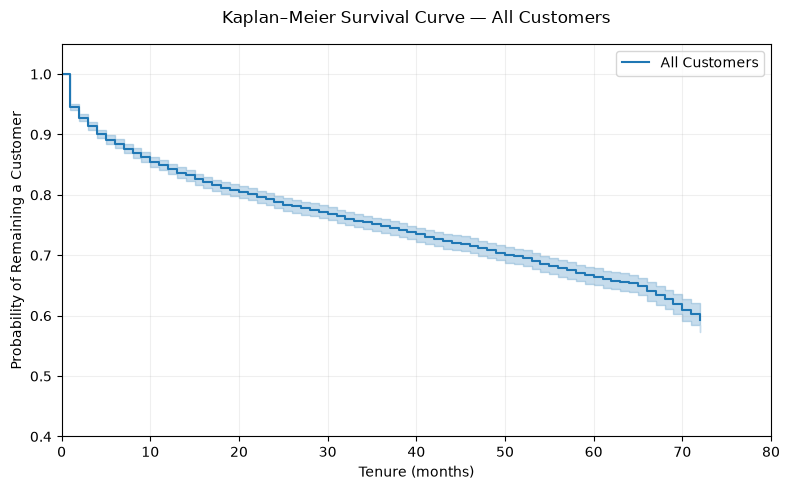

In [27]:
from lifelines import KaplanMeierFitter


# Create Kaplan-Meier model
kmf = KaplanMeierFitter()

# Fit model
kmf.fit(
    durations=df['tenure'],
    event_observed=(df['Churn'] == 'Yes'),
    label='All Customers'
)

# Create figure
fig, ax = plt.subplots(figsize=(8, 5))

# Plot survival curve
kmf.plot_survival_function(
    ax=ax,
    ci_show=True
)

# Labels
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Probability of Remaining a Customer')

ax.set_title(
    'Kaplan–Meier Survival Curve — All Customers',
    pad=15
)

# Give the curve some breathing room
ax.set_xlim(0, 80)
ax.set_ylim(0.4, 1.05)

# Grid
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

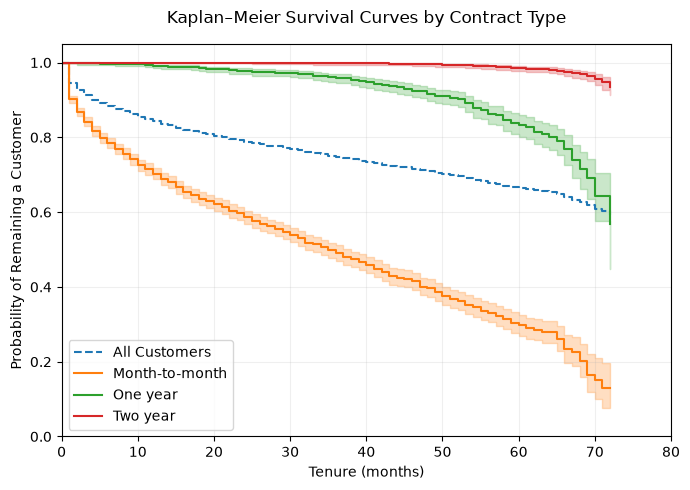

In [28]:
# New figure
fig, ax = plt.subplots(figsize=(7, 5))

# -----------------------------------
# All Customers benchmark
# -----------------------------------

kmf.fit(
    durations=df['tenure'],
    event_observed=(df['Churn'] == 'Yes'),
    label='All Customers'
)

kmf.plot_survival_function(
    ax=ax,
    ci_show=False,
    linestyle='--'
)


# -----------------------------------
# Contract type curves
# -----------------------------------

contract_types = ['Month-to-month', 'One year', 'Two year']

for contract in contract_types:

    contract_df = df[df['Contract'] == contract]

    kmf.fit(
        durations=contract_df['tenure'],
        event_observed=(contract_df['Churn'] == 'Yes'),
        label=contract
    )

    kmf.plot_survival_function(
        ax=ax,
        ci_show=True
    )


# -----------------------------------
# Formatting
# -----------------------------------

ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Probability of Remaining a Customer')

ax.set_title(
    'Kaplan–Meier Survival Curves by Contract Type',
    pad=15
)

ax.set_xlim(0, 80)
ax.set_ylim(0, 1.05)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

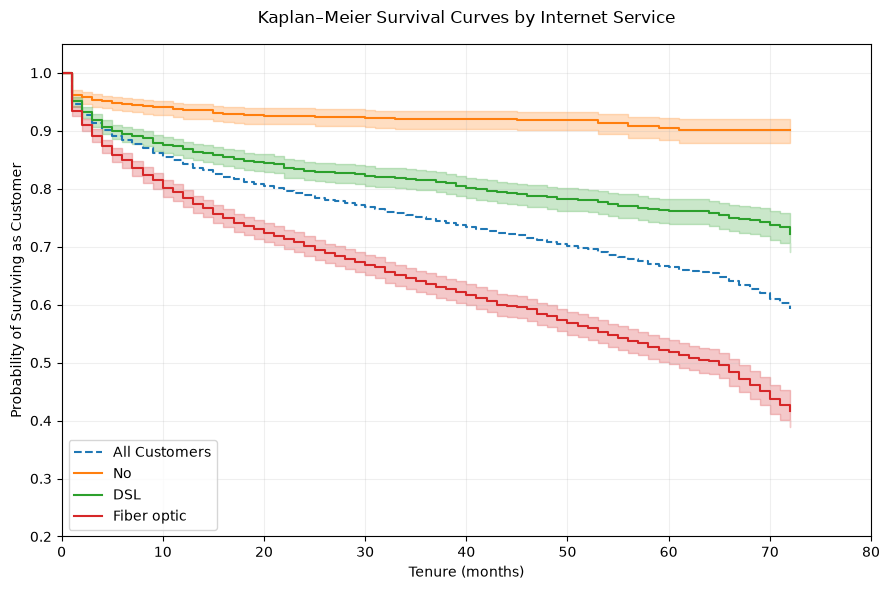

In [29]:
# New figure
fig, ax = plt.subplots(figsize=(9, 6))

# -----------------------------------
# All Customers benchmark
# -----------------------------------

kmf.fit(
    durations=df['tenure'],
    event_observed=(df['Churn'] == 'Yes'),
    label='All Customers'
)

kmf.plot_survival_function(
    ax=ax,
    ci_show=False,
    linestyle='--'
)


# -----------------------------------
# Internet Service curves
# -----------------------------------

internet_types = ['No', 'DSL', 'Fiber optic']

for internet in internet_types:

    internet_df = df[df['InternetService'] == internet]

    kmf.fit(
        durations=internet_df['tenure'],
        event_observed=(internet_df['Churn'] == 'Yes'),
        label=internet
    )

    kmf.plot_survival_function(
        ax=ax,
        ci_show=True
    )


# -----------------------------------
# Formatting
# -----------------------------------

ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Probability of Surviving as Customer')

ax.set_title(
    'Kaplan–Meier Survival Curves by Internet Service',
    pad=15
)

ax.set_xlim(0, 80)
ax.set_ylim(0.2, 1.05)

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()